<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp27.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Unlabelled pre-training set : (10000, 784)
Labelled fine-tuning set    : (1000, 784)
Test evaluation set         : (2000, 784)

=== Task 1: Greedy Layer-Wise Pre-Training ===
[RBM-1 (784->500)] Epoch  1/10 | Recon MSE: 0.0537
[RBM-1 (784->500)] Epoch 10/10 | Recon MSE: 0.0153
[RBM-2 (500->250)] Epoch  1/10 | Recon MSE: 0.0692
[RBM-2 (500->250)] Epoch 10/10 | Recon MSE: 0.0115


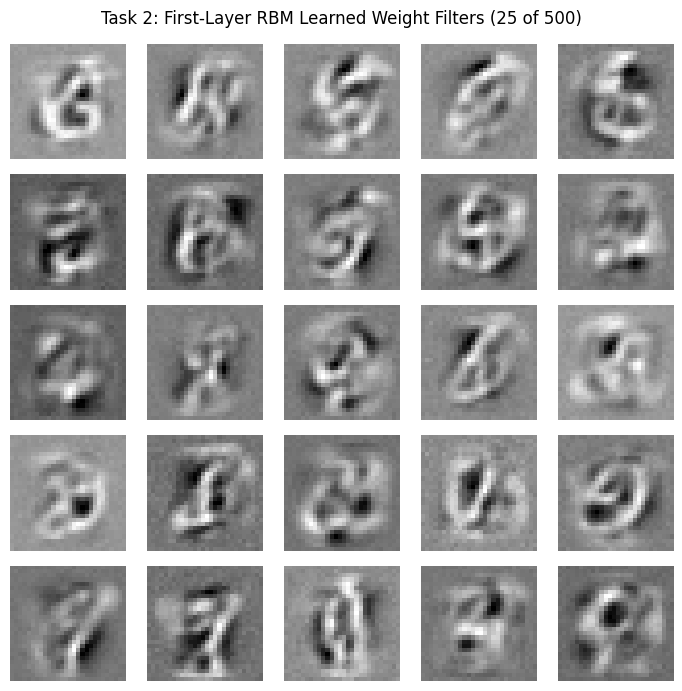


=== Task 3 & 4: Test Accuracy Comparison (1,000 Labelled Samples) ===
DBN Pre-Trained + Fine-Tuned Accuracy : 87.20%
Randomly Initialised Network Accuracy : 85.75%
Accuracy Gain from DBN Pre-Training   : +1.45%



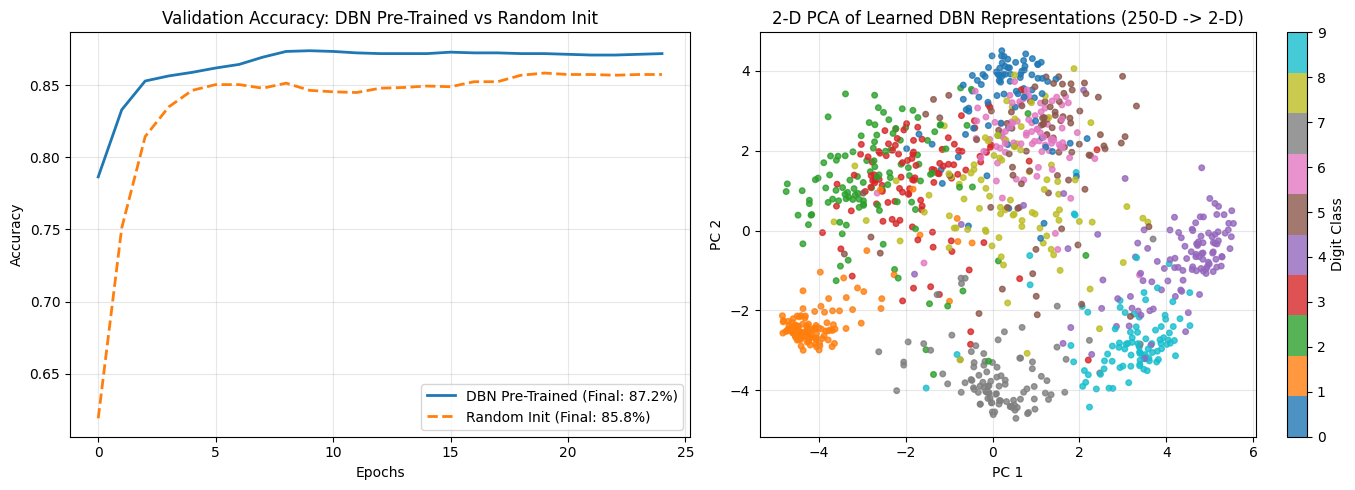

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit as sigmoid
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.decomposition import PCA

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# ==========================================
# Load MNIST: Unlabelled Pool + 1,000 Labelled for Fine-Tuning
# ==========================================
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = keras.datasets.mnist.load_data()

X_all = (X_train_raw.reshape(-1, 784) / 255.0).astype(np.float32)
X_test = (X_test_raw[:2000].reshape(-1, 784) / 255.0).astype(np.float32)
y_test = y_test_raw[:2000]

# Unlabelled data for greedy RBM pre-training (10,000 images)
X_unlabelled = X_all[:10000]

# Only 1,000 labelled images for supervised fine-tuning
X_labelled = X_all[10000:11000]
y_labelled = y_train_raw[10000:11000]

print(f"Unlabelled pre-training set : {X_unlabelled.shape}")
print(f"Labelled fine-tuning set    : {X_labelled.shape}")
print(f"Test evaluation set         : {X_test.shape}\n")

# ==========================================
# Task 1: Greedy Layer-Wise RBM Pre-Training (784 -> 500 -> 250)
# ==========================================
class RBM:
    def __init__(self, n_visible, n_hidden, seed=42):
        rng = np.random.default_rng(seed)
        self.W = rng.normal(0.0, 0.01, size=(n_visible, n_hidden)).astype(np.float32)
        self.a = np.zeros(n_visible, dtype=np.float32)
        self.b = np.zeros(n_hidden, dtype=np.float32)

    def prob_h_given_v(self, v):
        return sigmoid(v @ self.W + self.b)

    def prob_v_given_h(self, h):
        return sigmoid(h @ self.W.T + self.a)

    def fit(self, X, epochs=10, batch_size=64, lr=0.05, name="RBM"):
        n_samples = X.shape[0]
        for epoch in range(1, epochs + 1):
            perm = np.random.permutation(n_samples)
            X_shuf = X[perm]
            errs = []
            for i in range(0, n_samples, batch_size):
                v0 = X_shuf[i : i + batch_size]
                bs = v0.shape[0]

                # Positive phase
                p_h0 = self.prob_h_given_v(v0)
                h0 = (np.random.rand(*p_h0.shape) < p_h0).astype(np.float32)

                # Negative phase (CD-1)
                v1 = self.prob_v_given_h(h0)
                p_h1 = self.prob_h_given_v(v1)

                # Weight updates
                self.W += lr * ((v0.T @ p_h0) - (v1.T @ p_h1)) / bs
                self.a += lr * np.mean(v0 - v1, axis=0)
                self.b += lr * np.mean(p_h0 - p_h1, axis=0)

                errs.append(np.mean((v0 - v1) ** 2))
            if epoch == 1 or epoch == epochs:
                print(f"[{name}] Epoch {epoch:2d}/{epochs} | Recon MSE: {np.mean(errs):.4f}")

print("=== Task 1: Greedy Layer-Wise Pre-Training ===")
rbm1 = RBM(784, 500, seed=42)
rbm1.fit(X_unlabelled, epochs=10, batch_size=64, lr=0.05, name="RBM-1 (784->500)")

# Transform unlabelled data through RBM-1 to train RBM-2
H1_unlabelled = rbm1.prob_h_given_v(X_unlabelled)
rbm2 = RBM(500, 250, seed=43)
rbm2.fit(H1_unlabelled, epochs=10, batch_size=64, lr=0.05, name="RBM-2 (500->250)")

# ==========================================
# Task 2: Visualise Learned Weights of First Layer as Image Filters
# ==========================================
fig, axes = plt.subplots(5, 5, figsize=(7, 7))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(rbm1.W[:, i].reshape(28, 28), cmap="gray")
    ax.axis("off")
plt.suptitle("Task 2: First-Layer RBM Learned Weight Filters (25 of 500)", fontsize=12)
plt.tight_layout()
plt.show()

# ==========================================
# Task 3 & 4: Build DBN-Initialised vs Randomly-Initialised Keras Classifiers
# ==========================================
def build_classifier(pretrained_rbms=None):
    tf.random.set_seed(42)
    inputs = keras.Input(shape=(784,))
    h1 = layers.Dense(500, activation="sigmoid", name="dense_1")(inputs)
    h2 = layers.Dense(250, activation="sigmoid", name="dense_2")(h1)
    outputs = layers.Dense(10, activation="softmax", name="output")(h2)
    model = keras.Model(inputs=inputs, outputs=outputs)

    if pretrained_rbms is not None:
        r1, r2 = pretrained_rbms
        model.get_layer("dense_1").set_weights([r1.W, r1.b])
        model.get_layer("dense_2").set_weights([r2.W, r2.b])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.002),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# Task 3: Transfer RBM weights & fine-tune on 1,000 labelled samples
dbn_model = build_classifier(pretrained_rbms=(rbm1, rbm2))
hist_dbn = dbn_model.fit(
    X_labelled, y_labelled,
    validation_data=(X_test, y_test),
    epochs=25, batch_size=32, verbose=0
)

# Task 4: Train identical architecture from random initialisation
rand_model = build_classifier(pretrained_rbms=None)
hist_rand = rand_model.fit(
    X_labelled, y_labelled,
    validation_data=(X_test, y_test),
    epochs=25, batch_size=32, verbose=0
)

_, dbn_test_acc = dbn_model.evaluate(X_test, y_test, verbose=0)
_, rand_test_acc = rand_model.evaluate(X_test, y_test, verbose=0)

print("\n=== Task 3 & 4: Test Accuracy Comparison (1,000 Labelled Samples) ===")
print(f"DBN Pre-Trained + Fine-Tuned Accuracy : {dbn_test_acc * 100:.2f}%")
print(f"Randomly Initialised Network Accuracy : {rand_test_acc * 100:.2f}%")
print(f"Accuracy Gain from DBN Pre-Training   : {(dbn_test_acc - rand_test_acc) * 100:+.2f}%\n")

# ==========================================
# Task 5: Compare Accuracy Curves & Plot Learned Representations in 2-D
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Validation Accuracy Curves
axes[0].plot(hist_dbn.history["val_accuracy"], linewidth=2, label=f"DBN Pre-Trained (Final: {dbn_test_acc*100:.1f}%)")
axes[0].plot(hist_rand.history["val_accuracy"], linewidth=2, linestyle="--", label=f"Random Init (Final: {rand_test_acc*100:.1f}%)")
axes[0].set_title("Validation Accuracy: DBN Pre-Trained vs Random Init")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Extract 250-D learned representations from the DBN's second hidden layer & project to 2-D with PCA
feat_extractor = keras.Model(inputs=dbn_model.input, outputs=dbn_model.get_layer("dense_2").output)
reps_250d = feat_extractor.predict(X_test[:1000], verbose=0)
reps_2d = PCA(n_components=2, random_state=42).fit_transform(reps_250d)

scatter = axes[1].scatter(reps_2d[:, 0], reps_2d[:, 1], c=y_test[:1000], cmap="tab10", s=16, alpha=0.8)
axes[1].set_title("2-D PCA of Learned DBN Representations (250-D -> 2-D)")
axes[1].set_xlabel("PC 1")
axes[1].set_ylabel("PC 2")
axes[1].grid(True, alpha=0.3)
plt.colorbar(scatter, ax=axes[1], ticks=range(10), label="Digit Class")

plt.tight_layout()
plt.show()
